# Can You Tell a Valorant Player's Role From Their Stats?
**Pranav Meka** · Portfolio Project 1 · CU Boulder

## 1. The Dataset

In Valorant, every agent belongs to one of four roles:

| Role | Job on the team |
|---|---|
| **Duelist** | Take the first fight and create space |
| **Initiator** | Gather info and set up teammates (flashes, recon) |
| **Controller** | Block vision with smokes and control the map |
| **Sentinel** | Hold sites, watch flanks, slow down pushes |

This project uses professional match data from the **2026 Valorant Champions Tour (VCT)**, taken from the Kaggle dataset
*Valorant Champion Tour 2021-2026 Data* (`players_stats.csv`). Each row is one pro player's stats on one agent during one
stage of a tournament: kills, deaths, assists, first kills, headshot %, damage per round, and so on.

**Question:** If I hide the agent name, can a model tell which *role* a player was playing just from their numbers?

**Why it interests me:** I play Valorant, and I've always felt that roles change how a player's stat line looks.
Duelists should die first more often, and controllers should have more assists. This project tests whether that's true
in pro play, and how clearly the roles actually separate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score, f1_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ROLE_ORDER = ["duelist", "initiator", "controller", "sentinel"]

raw = pd.read_csv("players_stats.csv")
print(raw.shape)
raw.head()

(11821, 25)


,Tournament,Stage,Match Type,Player,Teams,Agents,Rounds Played,Rating,Average Combat Score,Kills:Deaths,...,First Deaths Per Round,Headshot %,Clutch Success %,Clutches (won/played),Maximum Kills in a Single Map,Kills,Deaths,Assists,First Kills,First Deaths
0,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,CHICHOO,EDward Gaming,astra,26,1.27,204,1.36,...,0.08,23%,20%,1/5,19,19,14,12,0,2
1,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,CHICHOO,EDward Gaming,cypher,18,1.14,192,1.56,...,0.06,28%,100%,1/1,14,14,9,3,2,1
2,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,CHICHOO,EDward Gaming,omen,17,0.84,131,0.73,...,0.12,29%,NaN,0/3,8,8,11,2,2,2
3,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,CHICHOO,EDward Gaming,"astra, cypher, omen",61,1.11,176,1.21,...,0.08,26%,22%,2/9,19,41,34,17,4,5
4,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,Jieni7,EDward Gaming,brimstone,18,1.39,187,1.63,...,0.00,31%,NaN,0/1,13,13,8,8,0,0


In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 11821 entries, 0 to 11820
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Tournament                      11821 non-null  str    
 1   Stage                           11821 non-null  str    
 2   Match Type                      11821 non-null  str    
 3   Player                          11821 non-null  str    
 4   Teams                           11821 non-null  str    
 5   Agents                          11821 non-null  str    
 6   Rounds Played                   11821 non-null  int64  
 7   Rating                          11630 non-null  float64
 8   Average Combat Score            11821 non-null  int64  
 9   Kills:Deaths                    11821 non-null  float64
 10  Kill, Assist, Trade, Survive %  11638 non-null  str    
 11  Average Damage Per Round        11642 non-null  float64
 12  Kills Per Round                 11821 non-n

### First cleanup: removing rows that would cause problems

Looking at the raw file, two kinds of rows need to go before anything else:

1. **"All Match Types" rows** are totals that repeat stats already in the other rows. Keeping them would count the same games twice.
2. **Rows with more than one agent** (e.g. `"fade, sova"`) mix stats from different agents. If a row combines a duelist and a
   controller, it has no single correct role, so I drop these too.

Then I map each agent to its role. This becomes the target **y**.

In [3]:
df = raw[raw["Match Type"] != "All Match Types"].copy()
df = df[~df["Agents"].str.contains(",")]

ROLES = {
    "duelist":    ["jett", "raze", "reyna", "phoenix", "yoru", "neon", "iso", "waylay"],
    "initiator":  ["sova", "breach", "skye", "kayo", "fade", "gekko", "tejo"],
    "controller": ["brimstone", "viper", "omen", "astra", "harbor", "clove"],
    "sentinel":   ["killjoy", "cypher", "sage", "chamber", "deadlock", "vyse", "veto"],
}
agent_to_role = {agent: role for role, agents in ROLES.items() for agent in agents}
df["Role"] = df["Agents"].map(agent_to_role)

print("Agents with no known role:", df.loc[df["Role"].isna(), "Agents"].unique())
df = df.dropna(subset=["Role"])   # drops 1 row for an agent I couldn't confirm the role of
print("Rows after cleanup:", len(df), "(from", len(raw), ")")

Agents with no known role: <StringArray>
['miks']
Length: 1, dtype: str
Rows after cleanup: 6481 (from 11821 )


### Converting text columns to numbers

Several stat columns are stored as text, like `"23%"` or `"1/5"`. I convert them to numbers:

- Strip the `%` from the percentage columns.
- Split `Clutches (won/played)` and turn it into **Clutches Played Per Round**. A clutch is when you're the last player
  alive on your team, so this measures how often a player ends up alone late in a round.
- Add one feature of my own: **Opening Duels Per Round** = first kills + first deaths per round. It measures how often a
  player is in the first fight of the round, whatever the result.

In [4]:
for col in ["Kill, Assist, Trade, Survive %", "Headshot %", "Clutch Success %"]:
    df[col] = df[col].str.rstrip("%").astype(float)

clutch = df["Clutches (won/played)"].str.split("/", expand=True).astype(float)
df["Clutches Played Per Round"] = clutch[1] / df["Rounds Played"]
df["Opening Duels Per Round"] = df["First Kills Per Round"] + df["First Deaths Per Round"]

df = df.rename(columns={"Kill, Assist, Trade, Survive %": "KAST %"})

### Choosing features

I only use **per-round** stats and percentages, not raw totals. Totals like `Kills` or `Deaths` mostly measure how
many rounds someone played. A player in a 5-map playoff run will have more kills than a player in a 2-map group stage,
whatever their role.

I also leave out `Player`, `Teams`, and `Tournament`. Pros usually stick to one role, so with the player's name the model
could just memorize "this player = duelist" instead of learning anything about how roles play.

`Stage` (Group Stage, Playoffs, etc.) is the one text field I keep as a feature, to check whether stats shift in
higher-pressure matches.

In [5]:
NUMERIC = ["Rating", "Average Combat Score", "Kills:Deaths", "KAST %", "Average Damage Per Round",
           "Kills Per Round", "Assists Per Round", "First Kills Per Round", "First Deaths Per Round",
           "Headshot %", "Clutch Success %", "Clutches Played Per Round", "Opening Duels Per Round"]
CATEGORICAL = ["Stage"]

data = df[NUMERIC + CATEGORICAL + ["Rounds Played", "Player", "Role"]].reset_index(drop=True)
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Rating,6353.0,1.00,0.31,0.03,0.79,0.98,1.19,2.81
Average Combat Score,6481.0,196.05,53.62,38.00,159.00,192.00,229.00,516.00
Kills:Deaths,6481.0,1.06,0.52,0.08,0.75,1.00,1.27,13.00
KAST %,6358.0,71.35,10.76,25.00,65.00,71.00,78.00,100.00
Average Damage Per Round,6361.0,128.78,33.88,34.00,106.00,127.00,150.00,353.00
Kills Per Round,6481.0,0.69,0.21,0.07,0.55,0.68,0.82,2.00
Assists Per Round,6481.0,0.28,0.15,0.00,0.17,0.25,0.36,1.19
First Kills Per Round,6361.0,0.10,0.07,0.00,0.05,0.09,0.14,0.53
First Deaths Per Round,6361.0,0.10,0.07,0.00,0.05,0.09,0.14,0.71
Headshot %,6357.0,28.70,9.36,4.00,22.00,28.00,34.00,73.00


## 2. Feature Engineering

### 2a. Class (im)balance

Role
duelist       0.292
initiator     0.247
controller    0.316
sentinel      0.145
Name: count, dtype: float64


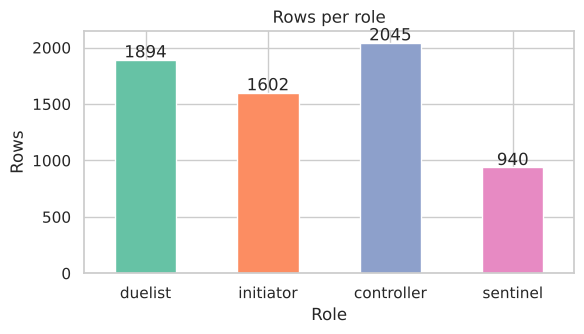

In [6]:
counts = data["Role"].value_counts().reindex(ROLE_ORDER)
print((counts / counts.sum()).round(3))

ax = counts.plot(kind="bar", color=sns.color_palette("Set2", 4), figsize=(6, 3.5), rot=0)
ax.set_title("Rows per role"); ax.set_ylabel("Rows")
for i, v in enumerate(counts): ax.text(i, v + 20, v, ha="center")
plt.tight_layout(); plt.show()

**Result:** The classes are **moderately imbalanced**. Sentinels make up only about 15% of rows, while controllers make
up about 31%. This makes sense: a pro team usually runs two controllers or a double-initiator setup, but rarely two
sentinels.

What this means for the model:
- **Accuracy alone would mislead.** A model can score well while mostly ignoring sentinels, so I'll report per-class recall and F1 too.
- I'll train with `class_weight="balanced"`, which makes mistakes on the smaller class count more.

### 2b. Feature histograms and outliers

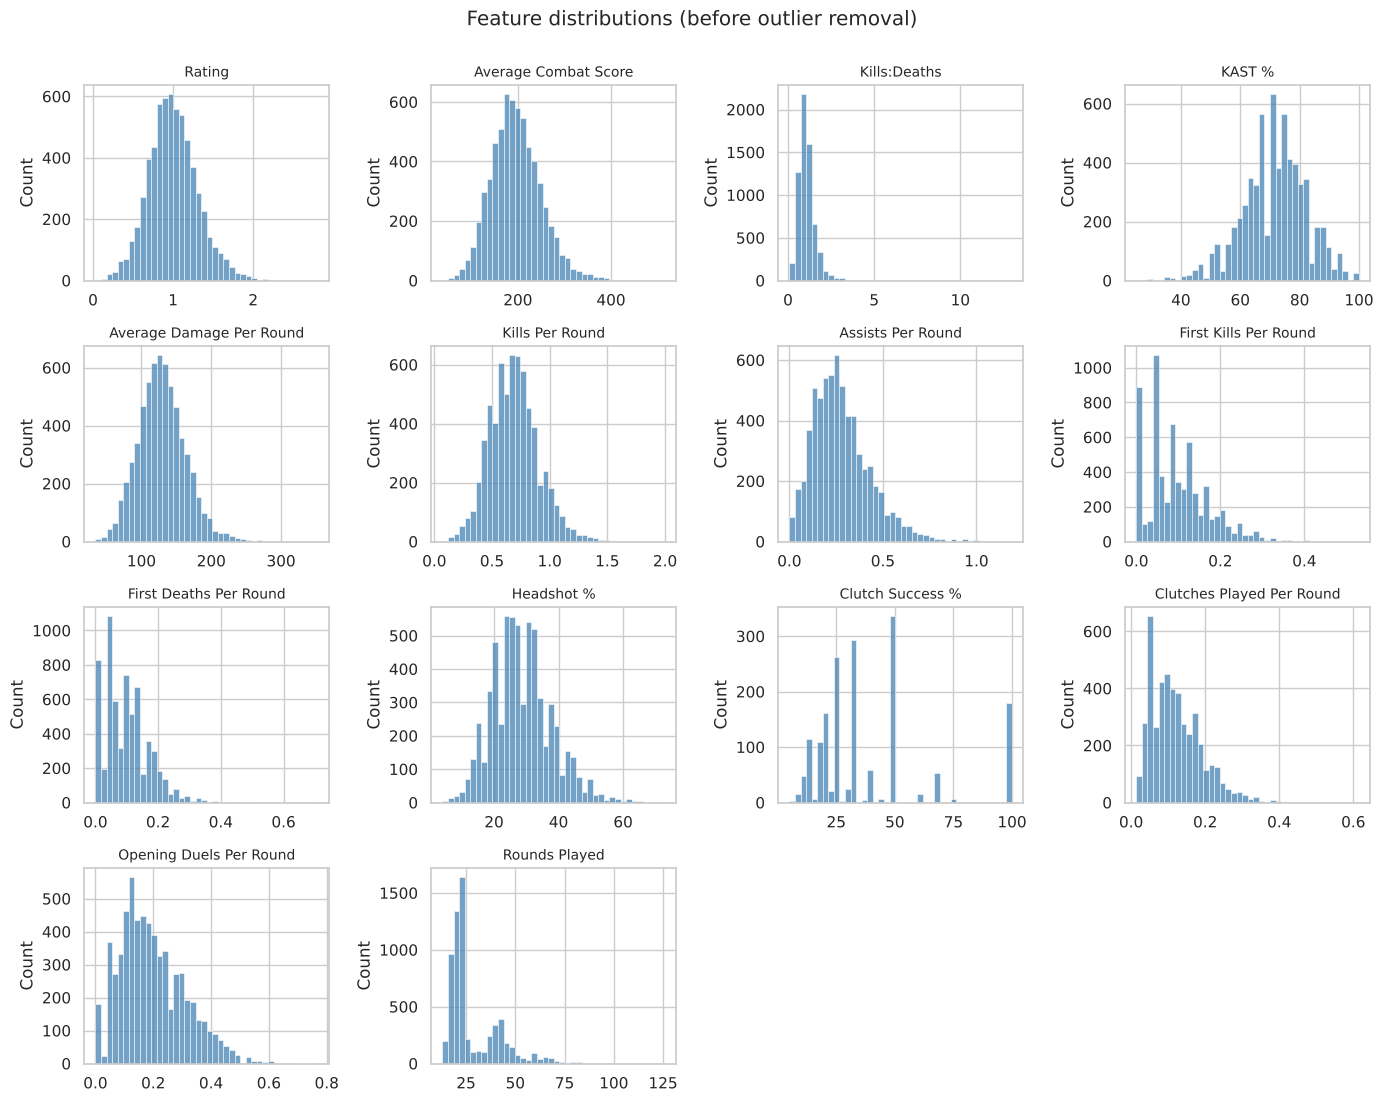

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(14, 11))
for ax, col in zip(axes.flat, NUMERIC + ["Rounds Played"]):
    sns.histplot(data[col].dropna(), bins=40, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=10); ax.set_xlabel("")
for ax in axes.flat[len(NUMERIC) + 1:]: ax.remove()
plt.suptitle("Feature distributions (before outlier removal)", y=1.0)
plt.tight_layout(); plt.show()

**What the histograms show:**
- Most features look roughly bell-shaped, which suits logistic regression.
- **Kills:Deaths** has a long right tail: a few rows reach K:D values like 13. These come from players with very few deaths
  over a small number of rounds. That's not a real skill level, just a small sample.
- **Rounds Played** starts at 13 and is right-skewed. Rows with few rounds give noisier per-round stats.

**How I remove outliers:** I use a wide IQR fence (**3 × IQR** instead of the usual 1.5 ×) on the per-round stats.
The usual 1.5 × rule would cut off *real* role signal. For example, duelists naturally have far more first kills than
everyone else, and I don't want to delete exactly the rows the model needs. 3 × IQR only removes the extreme cases.

In [8]:
OUTLIER_COLS = ["Kills:Deaths", "Kills Per Round", "Assists Per Round", "First Kills Per Round",
                "First Deaths Per Round", "Average Damage Per Round", "Headshot %"]

def iqr_mask(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s.isna() | s.between(q1 - k * iqr, q3 + k * iqr)   # keep missing values; they're handled in 2c

keep = np.logical_and.reduce([iqr_mask(data[c]) for c in OUTLIER_COLS])
removed = data.loc[~keep]
print(f"Removed {len(removed)} rows ({len(removed)/len(data):.1%})")
print("Removed rows by role:", removed["Role"].value_counts().to_dict())
print("Median rounds played, removed vs kept:",
      removed["Rounds Played"].median(), "vs", data.loc[keep, "Rounds Played"].median())

data = data.loc[keep].reset_index(drop=True)

Removed 83 rows (1.3%)
Removed rows by role: {'controller': 31, 'initiator': 25, 'duelist': 17, 'sentinel': 10}
Median rounds played, removed vs kept: 16.0 vs 23.0


The removed rows have fewer rounds played than average, which supports the idea that they're small-sample flukes rather
than real playstyles. They're also spread across all roles, so removing them doesn't hurt any one class.

### 2c. Imputing missing values

In [9]:
missing = data[NUMERIC].isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["percent"] = (missing["missing"] / len(data) * 100).round(1)
missing

,missing,percent
Rating,128,2.0
KAST %,123,1.9
Average Damage Per Round,120,1.9
First Kills Per Round,120,1.9
First Deaths Per Round,120,1.9
Headshot %,124,1.9
Clutch Success %,4706,73.6
Clutches Played Per Round,1813,28.3
Opening Duels Per Round,120,1.9


There are two different kinds of missing data here, so I handle them differently:

| Column(s) | Why it's missing | What I do |
|---|---|---|
| **Clutch Success %** | Missing for over half the rows, since you can't have a success rate without clutch attempts | **Drop the column.** Filling in over half of a column would be mostly made-up data |
| **Clutches Played Per Round** | Missing when the clutch record is blank, which means the player had no clutches | **Fill with 0.** Here, missing actually means zero |
| **Rating, KAST %, ADR, First Kills/Deaths, Headshot %** | About 2% of rows, where the source site didn't record the stat | **Fill with the median for that role** |

**Why fill by role?** The median first-kill rate for a duelist is very different from a controller's. A single overall
median would pull every role toward the middle.

> **Note on data leakage:** Strictly speaking, imputation should use only the training data, because the test set should
> stay unseen. Here only about 2% of values are filled, and a median over 6,000 rows barely moves, so the effect is tiny.
> I note it because in a production model, I'd fit the imputer on the training split only. (There's a second catch:
> filling by role uses the label itself. That's acceptable for this small share of rows, but it's another reason to keep
> imputation inside the training data in a real project.)

In [10]:
data = data.drop(columns=["Clutch Success %"])
NUMERIC.remove("Clutch Success %")

data["Clutches Played Per Round"] = data["Clutches Played Per Round"].fillna(0)

for col in NUMERIC:
    data[col] = data.groupby("Role")[col].transform(lambda s: s.fillna(s.median()))

# Opening Duels depends on First Kills/Deaths, so rebuild it after filling those in
data["Opening Duels Per Round"] = data["First Kills Per Round"] + data["First Deaths Per Round"]

print("Missing values left:", int(data[NUMERIC].isna().sum().sum()))

Missing values left: 0


### 2d. Encoding text fields

- **Stage** has no natural order (Swiss Stage isn't "more" than Group Stage), so I **one-hot encode** it.
- **Role** is the target. I keep it as text labels, since scikit-learn handles text labels for classification directly
  and it keeps the confusion matrix readable.

In [11]:
data = pd.get_dummies(data, columns=["Stage"], prefix="Stage", dtype=int)
STAGE_COLS = [c for c in data.columns if c.startswith("Stage_")]
print(STAGE_COLS)
data[STAGE_COLS].head()

['Stage_Group Stage', 'Stage_Main Event', 'Stage_Playoffs', 'Stage_Swiss Stage']


,Stage_Group Stage,Stage_Main Event,Stage_Playoffs,Stage_Swiss Stage
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,1,0
4,0,0,1,0


### 2e. Correlated columns

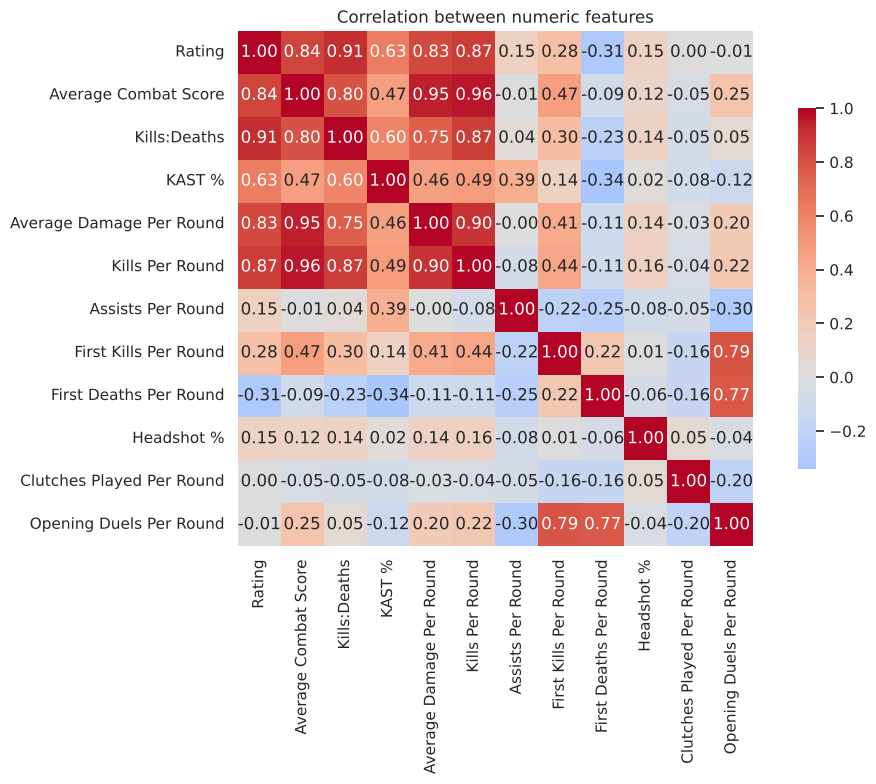

In [12]:
plt.figure(figsize=(11, 8))
corr = data[NUMERIC].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation between numeric features")
plt.tight_layout(); plt.show()

In [13]:
THRESHOLD = 0.90
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s > THRESHOLD].sort_values(ascending=False)
print("Highly correlated pairs (|r| > 0.90):")
print(pairs.round(3))

Highly correlated pairs (|r| > 0.90):
Average Combat Score      Kills Per Round             0.964
                          Average Damage Per Round    0.951
Rating                    Kills:Deaths                0.913
Average Damage Per Round  Kills Per Round             0.902
dtype: float64


Two groups of columns are near-duplicates:

- **Average Combat Score (ACS)**, **Average Damage Per Round (ADR)** and **Kills Per Round** measure almost the same thing.
  This makes sense: ACS is mostly calculated from damage and kills. I keep **Kills Per Round**, the simplest of the three,
  and drop ACS and ADR.
- **Rating** and **Kills:Deaths** have a correlation of 0.91. Rating is a summary score built from the other stats, so
  it adds little that's new. I keep **Kills:Deaths**, which is easier to explain, and drop Rating.

Keeping near-duplicate columns adds no new information and makes the model's coefficients harder to interpret, because
the model can split the same effect between two columns in any way.

(`Opening Duels Per Round` is the sum of first kills and first deaths, so it overlaps with them too. I keep it because it
measures *involvement* in the first fight, which neither column shows alone, and the model's regularization handles the overlap.)

In [14]:
TO_DROP = ["Average Combat Score", "Average Damage Per Round", "Rating"]
FEATURES = [c for c in NUMERIC if c not in TO_DROP] + STAGE_COLS
print(len(FEATURES), "features:", FEATURES)

13 features: ['Kills:Deaths', 'KAST %', 'Kills Per Round', 'Assists Per Round', 'First Kills Per Round', 'First Deaths Per Round', 'Headshot %', 'Clutches Played Per Round', 'Opening Duels Per Round', 'Stage_Group Stage', 'Stage_Main Event', 'Stage_Playoffs', 'Stage_Swiss Stage']


## 3. Looking for Clusters (without using y)

Before training anything, I check whether the data forms natural groups **on its own**, without telling it the roles.
If the clusters match the roles, the roles leave a clear mark on the stats.

I use only the numeric stat features here (not Stage), scale them so that no single feature dominates, and run
**K-Means** for k = 2 to 8.

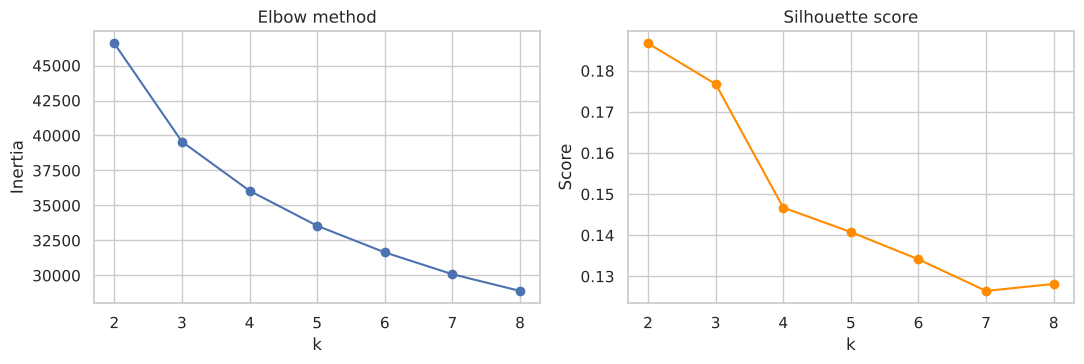

{2: np.float64(0.187), 3: np.float64(0.177), 4: np.float64(0.147), 5: np.float64(0.141), 6: np.float64(0.134), 7: np.float64(0.126), 8: np.float64(0.128)}


In [15]:
STAT_FEATURES = [c for c in FEATURES if not c.startswith("Stage_")]
X_scaled = StandardScaler().fit_transform(data[STAT_FEATURES])

ks = range(2, 9)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_, sample_size=3000, random_state=RANDOM_STATE))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(ks, inertias, "o-"); a1.set(title="Elbow method", xlabel="k", ylabel="Inertia")
a2.plot(ks, silhouettes, "o-", color="darkorange"); a2.set(title="Silhouette score", xlabel="k", ylabel="Score")
plt.tight_layout(); plt.show()
print(dict(zip(ks, np.round(silhouettes, 3))))

Neither chart shows a sharp elbow, and the silhouette scores are low, so **the data doesn't split into well-separated
clusters**. Player stats form one continuous cloud rather than four separate islands.

Since there are four roles, I take **k = 4** and check whether those four clusters line up with the roles anyway.

Variance explained by 2 PCA components: 0.568


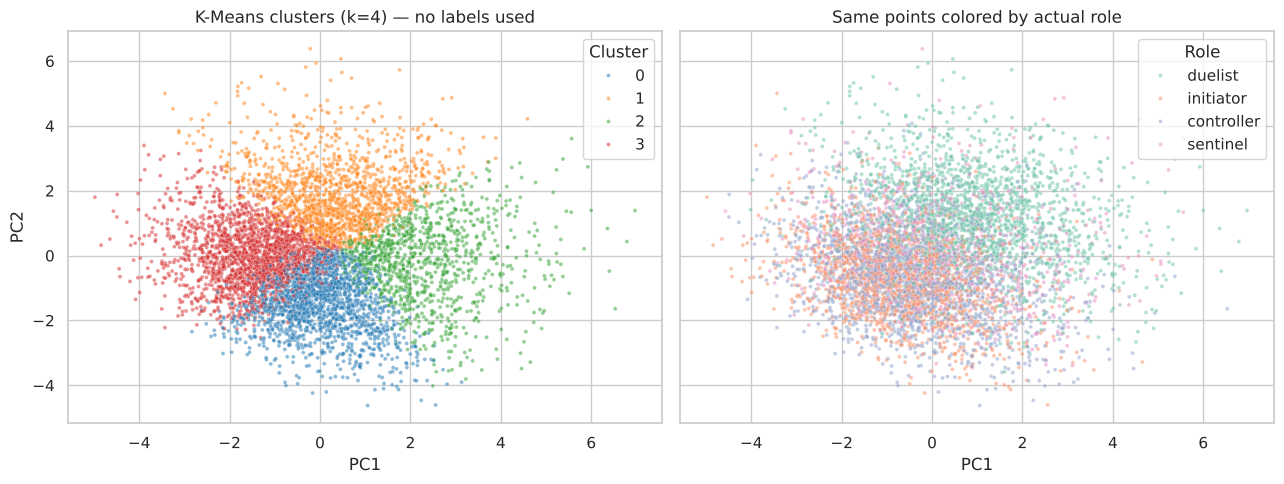

In [16]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
data["Cluster"] = km4.labels_

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)
print("Variance explained by 2 PCA components:", pca.explained_variance_ratio_.sum().round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=data["Cluster"], palette="tab10", s=8, alpha=.5, ax=a1, legend="full")
a1.set(title="K-Means clusters (k=4) — no labels used", xlabel="PC1", ylabel="PC2")
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=data["Role"], hue_order=ROLE_ORDER, palette="Set2", s=8, alpha=.5, ax=a2)
a2.set(title="Same points colored by actual role", xlabel="PC1")
plt.tight_layout(); plt.show()

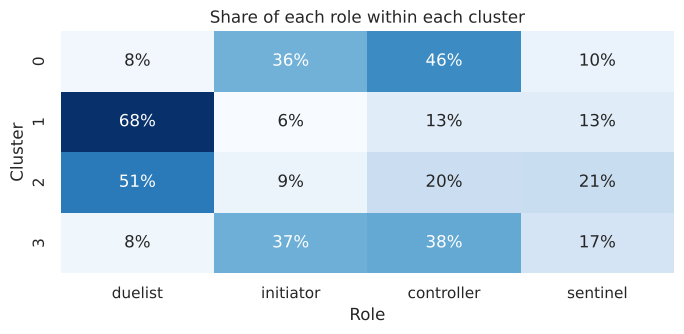

Cluster,0,1,2,3
Kills:Deaths,1.21,0.87,1.57,0.72
KAST %,78.86,65.25,78.25,64.68
Kills Per Round,0.73,0.65,0.96,0.52
Assists Per Round,0.39,0.20,0.22,0.25
First Kills Per Round,0.06,0.14,0.18,0.05
First Deaths Per Round,0.06,0.18,0.09,0.08
Headshot %,29.21,27.50,30.95,27.75
Clutches Played Per Round,0.08,0.06,0.08,0.12
Opening Duels Per Round,0.12,0.32,0.27,0.13


In [17]:
ct = pd.crosstab(data["Cluster"], data["Role"], normalize="index").reindex(columns=ROLE_ORDER)
plt.figure(figsize=(7, 3.5))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("Share of each role within each cluster"); plt.tight_layout(); plt.show()

# What each cluster looks like on average (in original units)
data.groupby("Cluster")[STAT_FEATURES].mean().round(2).T

**What the clusters show** (cluster numbers match the tables above):

| Cluster | Stat profile | Main roles |
|---|---|---|
| **1** | Most opening duels, and more first *deaths* than first kills | **68% duelists** |
| **2** | Best fraggers: highest kills/round, K:D and first kills | 51% duelists |
| **0** | Most assists, high KAST, rarely in the first fight | 82% initiators + controllers |
| **3** | Fewest kills, lowest K:D, most clutch situations | 75% initiators + controllers |

So without ever seeing the labels, K-Means found a real split: **"entry" players vs. "support" players**.
Duelists stand out because they take the first fight of the round, often by dying first to open space for the team.

What it *couldn't* do:
- **Initiators and controllers end up in the same clusters.** Their stat lines look very similar.
- **Sentinels don't get a cluster of their own.** They're spread across all four.
- Two of the clusters split players by **how well they played** (cluster 2 vs. 1, cluster 0 vs. 3) rather than by role.

Low silhouette scores and overlapping clouds in the PCA plot mean role is a real but **weak** signal in these stats.
A supervised model, which gets the labels during training, should do better than clustering, but probably won't be near-perfect.

## 4. Train/Test Split

I hold out 20% of the data for testing. One important detail: **the split is grouped by player.**

The same pro player shows up in many rows (different events, different agents), and players have personal habits,
like a high headshot rate. With a normal random split, the same player could land in both train and test, and the model
could score well just by recognizing that player's stat pattern. Grouping by player means **every player in the test set
is someone the model has never seen**, which is a more honest test.

In [18]:
X = data[FEATURES]
y = data["Role"]
groups = data["Player"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {len(X_train)} rows, {groups.iloc[train_idx].nunique()} players")
print(f"Test:  {len(X_test)} rows, {groups.iloc[test_idx].nunique()} players")
print("Players in both:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}
            ).reindex(ROLE_ORDER).round(3)

Train: 5077 rows, 227 players
Test:  1321 rows, 57 players
Players in both: 0


,train,test
Role,,
duelist,0.297,0.279
initiator,0.241,0.266
controller,0.320,0.296
sentinel,0.142,0.158


The role mix is similar in train and test, so the grouped split didn't create a skewed test set.

## 5. Choosing the Algorithm

The target is a category with four values, so this is a **classification** problem. I use **Logistic Regression**
(multi-class), which suits this project because:
- It's simple and fast, and its coefficients show *which stats* point toward each role.
- With `class_weight="balanced"`, it accounts for the smaller sentinel class.

I compare it against two other models:
1. **Baseline:** always guess the most common role. Any useful model has to beat this.
2. **Polynomial Logistic Regression:** the same model with degree-2 polynomial features, which lets it use combinations
   like "high first kills **and** low assists." This checks whether a more flexible model helps.

Features are scaled inside a pipeline, so the scaler is fit on the training data only.

## 6. Training the Models

In [19]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
).fit(X_train, y_train)

poly_logreg = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=5000, C=0.5, random_state=RANDOM_STATE),
).fit(X_train, y_train)
print("Models trained.")

Models trained.


## 7. Testing the Models

In [20]:
models = {"Baseline (most common role)": baseline,
          "Logistic Regression": logreg,
          "Polynomial Logistic Regression (deg 2)": poly_logreg}

rows = []
for name, m in models.items():
    rows.append({"Model": name,
                 "Train accuracy": accuracy_score(y_train, m.predict(X_train)),
                 "Test accuracy":  accuracy_score(y_test,  m.predict(X_test)),
                 "Test macro F1":  f1_score(y_test, m.predict(X_test), average="macro")})
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Train accuracy,Test accuracy,Test macro F1
Model,,,
Baseline (most common role),0.320,0.296,0.114
Logistic Regression,0.534,0.525,0.516
Polynomial Logistic Regression (deg 2),0.552,0.518,0.504


**How to read this table:**
- **Macro F1** averages the F1 score across the four roles equally, so a model can't score well by ignoring sentinels.
  It's the fairer score here.
- **Train vs. test accuracy:** if train were much higher than test, the model would be memorizing (overfitting). A small
  gap means it generalizes to players it hasn't seen.

## 8. Model Measurement: Confusion Matrix

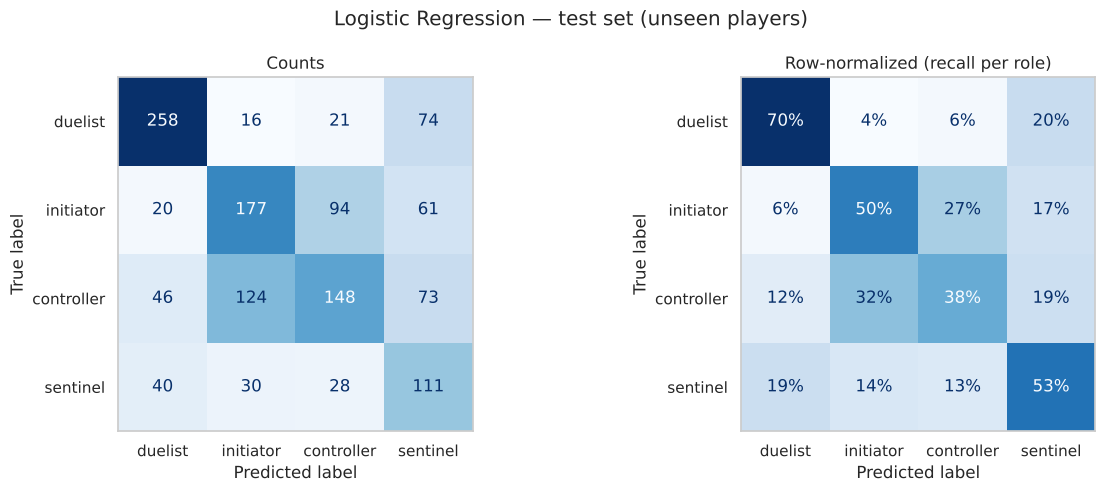

              precision    recall  f1-score   support

     duelist      0.709     0.699     0.704       369
   initiator      0.510     0.503     0.506       352
  controller      0.509     0.379     0.434       391
    sentinel      0.348     0.531     0.420       209

    accuracy                          0.525      1321
   macro avg      0.519     0.528     0.516      1321
weighted avg      0.539     0.525     0.527      1321



In [21]:
best = logreg
y_pred = best.predict(X_test)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=ROLE_ORDER, cmap="Blues", ax=a1, colorbar=False)
a1.set_title("Counts")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=ROLE_ORDER, normalize="true",
                                        values_format=".0%", cmap="Blues", ax=a2, colorbar=False)
a2.set_title("Row-normalized (recall per role)")
for a in (a1, a2): a.grid(False)
plt.suptitle("Logistic Regression — test set (unseen players)")
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, labels=ROLE_ORDER, digits=3))

### Which stats point to which role?

Since the features are scaled, the logistic regression coefficients can be compared directly. A positive value means
"more of this stat → more likely this role."

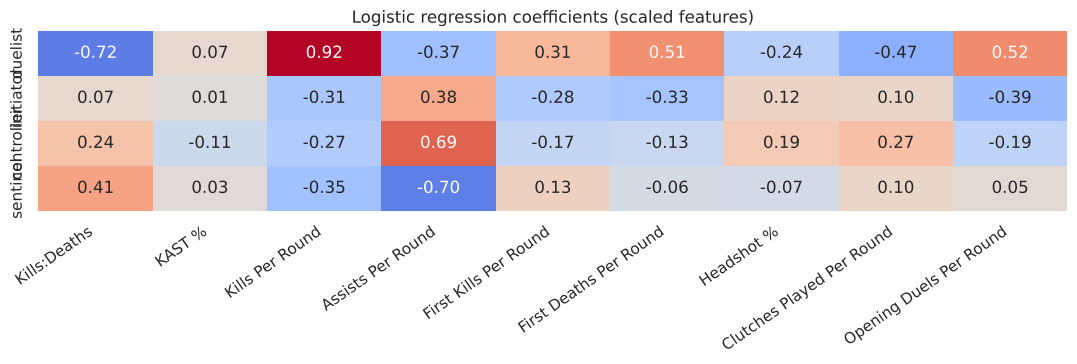

In [22]:
coefs = pd.DataFrame(best[-1].coef_, index=best[-1].classes_, columns=FEATURES).reindex(ROLE_ORDER)
stat_coefs = coefs[STAT_FEATURES]

plt.figure(figsize=(11, 3.8))
sns.heatmap(stat_coefs, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=False)
plt.title("Logistic regression coefficients (scaled features)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

In [23]:
# Average stats per role, for plain-language interpretation
data.groupby("Role")[STAT_FEATURES].mean().reindex(ROLE_ORDER).round(3)

,Kills:Deaths,KAST %,Kills Per Round,Assists Per Round,First Kills Per Round,First Deaths Per Round,Headshot %,Clutches Played Per Round,Opening Duels Per Round
Role,,,,,,,,,
duelist,1.071,69.956,0.750,0.206,0.150,0.148,27.532,0.059,0.298
initiator,0.980,71.946,0.630,0.312,0.061,0.066,28.713,0.095,0.127
controller,1.036,72.322,0.662,0.342,0.073,0.078,29.498,0.103,0.151
sentinel,1.086,69.898,0.698,0.195,0.105,0.095,28.988,0.103,0.200


## 9. Summary

### What I learned about the data

- **Duelists are easy to spot. The other three roles are not.** The model correctly identified **70%** of duelists
  in the test set. The clearest sign is involvement in the first fight of the round: duelists average about
  **0.30 opening duels per round**, twice the rate of initiators and controllers. Interestingly, the model treats
  *first deaths* as a stronger duelist signal than first kills. Dying first to make space for the team is part of the job.
- **Assists separate the support roles from the rest.** High assists push the model toward controller and initiator,
  and away from sentinel and duelist.
- **Initiators and controllers are the most confused pair.** 124 controllers were predicted as initiators, and 94
  initiators as controllers. Both roles support the team with utility, and the scoreboard stats in this dataset
  don't capture *what kind* of utility (smokes vs. flashes/recon).
- **Sentinels are the hardest role.** Their stats sit in the middle on almost every measure. The model only finds them
  (53% recall) by guessing "sentinel" often, which gives low precision (35%). The reverse mistake is common too: 20% of duelists were labeled sentinels.
  Sentinels like Chamber play an aggressive, gun-focused style, so some of them produce stat lines that look like a duelist's.
- **Most of the variation in pro stats is about *how well* someone played, not *what role* they played.** The clustering
  showed this before any model was trained.

### How effective was the model?

| Model | Test accuracy | Test macro F1 |
|---|---|---|
| Baseline (always guess the most common role) | 29.6% | 0.11 |
| **Logistic Regression** | **52.5%** | **0.52** |
| Polynomial Logistic Regression | 51.8% | 0.50 |

- Logistic regression is **much better than guessing**: 52.5% vs. a 29.6% baseline on a 4-class problem, tested on
  **players the model never saw** during training.
- Train and test accuracy are close (53.4% vs. 52.5%), so the model **isn't overfitting**.
- The polynomial model fit the training data slightly better but did **slightly worse** on the test set, so the extra
  complexity didn't help. The limit is the **features**, not the model. Scoreboard stats only carry part of the
  information about role.

**Bottom line:** A player's stat line clearly shows whether they're an entry player (duelist), and gives a partial hint
about the other roles. To tell controllers, initiators and sentinels apart reliably, you'd need data on *utility*:
smokes placed, flashes thrown, enemies revealed, or traps triggered.

### What I'd do next
- Add utility stats (e.g. from round-by-round data) to separate the three support roles.
- Try a tree-based model (Random Forest) to see whether nonlinear patterns help.
- Predict at the **map** level instead of the tournament-stage level, giving more, but noisier, rows.
- I also looked at a round-level win/loss file from the same dataset, but rejected it because its `Method` column
  (e.g. "Elimination" vs. "Eliminated") directly reveals the outcome. Using it would have been data leakage.